# Week 8, Tuesday

## Reminders

Please schedule to meet with Luke (see Luke's Canvas Announcement) during this week, in anticipation of the Final Project Preparation assignment due Friday.

It's fine to use this meeting to discuss your ideas with Luke, or to ask Luke to help you come up with ideas.

Luke and I will try to have the midterms graded and returned next week.

## Gradient Descent for one-variable Linear Regression

Our medium-term goal is to see how to use Gradient Descent to seek effective weights and biases in a Neural Network.  Before that, today, we will see Gradient Descent in a simpler setting, for Linear Regression in the setting with just one predictor.  For Linear Regression, there are alternatives to Gradient Descent, related to the Normal Equation which provides an explicit solution for "the best slope and y-intercept".  In the context of Neural Networks, there is no explicit solution in general, so a variant of Gradient Descent is typically used.

**Starting question**: What do we mean by "the best slope and y-intercept"?

In [1]:
from sklearn.datasets import make_regression
from matplotlib import pyplot as plt

In [13]:
n = 100
x, y, coef = make_regression(n_samples=n, n_features=1, random_state=0, noise=10, bias=-5, coef=True)
x = x.reshape(-1) # to avoid broadcasting issues below

In [14]:
coef

array(42.38550486)

True values are w = 42.385, b = -5

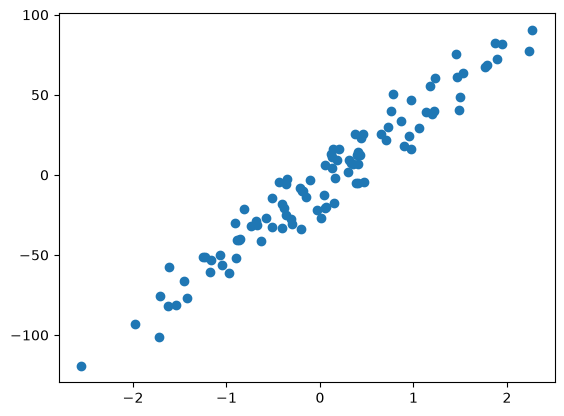

In [15]:
fig, ax = plt.subplots()
ax.scatter(x, y);

In [16]:
# starting values, I'll choose randomly
w = 3
b = 10

In [19]:
(2*(w*x + b - y)*x).shape

(100,)

In [20]:
# manually define partial deriv of the MSE loss function wrt w.
def Lw(w, b, x, y):
    return (2*(w*x+b-y)*x).mean()

In [21]:
def Lb(w, b, x, y):
    return (2*(w*x+b-y)).mean()

In [28]:
learn_rate = 0.01
epochs = 100000 # repeat update step this many times

for i in range(epochs):
    grad_w = Lw(w, b, x, y)
    grad_b = Lb(w, b, x, y)
    w = w - learn_rate*grad_w
    b = b - learn_rate*grad_b

In [29]:
w

np.float64(42.619430291366776)

In [30]:
b

np.float64(-5.814181827030694)

In [31]:
from sklearn.linear_model import LinearRegression

In [32]:
reg = LinearRegression()

In [33]:
reg.fit(x.reshape(-1,1), y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[42.62]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-5.814
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[10.08]


In [34]:
reg.coef_

array([42.61943029])

In [35]:
reg.intercept_

np.float64(-5.814181827030725)

In [ ]:
# MSE loss function
def L(w,b,x,y):
    return ((w*x+b-y)**2).mean()

In [37]:
L(42.6194, -5.814, x, y)

np.float64(114.17148620153247)

In [ ]:
# true values give a worse loss
L(42.385, -5, x, y)

np.float64(114.86757117446717)

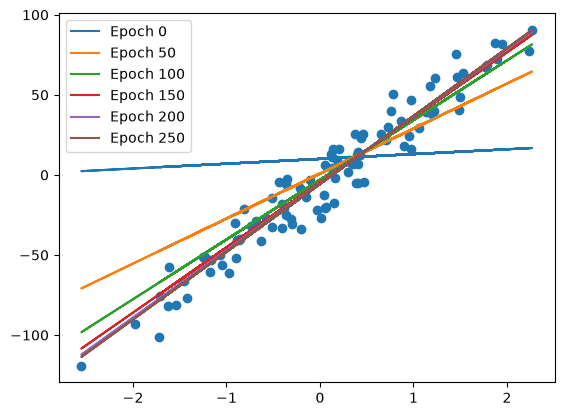

In [42]:
w = 3
b = 10

fig, ax = plt.subplots()
ax.scatter(x, y)

learn_rate = 0.01
epochs = 300 # repeat update step this many times

for i in range(epochs):
    if i%50 == 0:
        ax.plot(x, w*x + b, label=f"Epoch {i}")
    grad_w = Lw(w, b, x, y)
    grad_b = Lb(w, b, x, y)
    w = w - learn_rate*grad_w
    b = b - learn_rate*grad_b

ax.legend()

Updates for next time:
* Rather than using all data at each update, we will divide the data into "mini-batches"
* Increase the number of predictors

For neural networks:
* Need to be more careful with our starting values and/or try multiple starting values
* Partial derivatives will take much more strategy to compute; the process used is called "back-propagation"